# A/B 테스트: Fast Food Marketing Campaign

## 데이터
- **출처**: [Kaggle — Fast Food Marketing Campaign A/B Test](https://www.kaggle.com/datasets/chebotinaa/fast-food-marketing-campaign-ab-test) (IBM Watson Analytics 예제 데이터)
- **파일**: `WA_Marketing-Campaign.csv` (아래 첫 코드 셀에서 자동으로 내려받음)
- **규모**: 548행 = 매장 137곳 × 4주

## 시나리오
한 패스트푸드 체인이 신메뉴를 메뉴에 추가할 계획이며, 세 가지 마케팅 프로모션 중 무엇을 쓸지 아직 정하지 못했다. 가장 효과적인 프로모션을 정하기 위해, 무작위로 선정한 몇 개 시장(10곳)의 매장 137곳에서 신메뉴를 출시하고 매장마다 프로모션 하나를 적용해 처음 4주 동안의 **주간 신메뉴 매출**을 기록했다.

## 분석 목표
세 프로모션 중 신메뉴 매출에 가장 효과적인 것을 통계적 검정으로 판단하고, 출시 / 보류 / 데이터 추가 수집 중 하나를 근거와 함께 제안한다.

## 노트북 구성
1. **데이터 점검**: 결측·중복·배정 일관성·SRM·공변량 균형
2. **질문과 가설 정하기**
3. **검정 고르기**: 정규성·등분산 점검 후 검정 선택
4. **검정 수행과 결과 보고**: 점추정 · 95% 신뢰구간 · 효과크기 + 보조 분석 + MDE
5. **한 걸음 더 (B. 가정이 깨졌다면)**: 분석 방법·이상치에 따른 결론 비교 + 시장 보정 분석
6. **의사결정**: 결론, 의사결정, 한계

In [1]:
# 환경 설정 및 데이터 로드 
# !pip install kagglehub ipywidgets  # 처음 한 번만 설치

import os
import shutil
from datetime import datetime
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 데이터셋 다운로드 → 노트북과 같은 폴더에 CSV 복사 (CSV는 .gitignore로 커밋 제외)
csv_file = "WA_Marketing-Campaign.csv"
if not os.path.exists(csv_file):
    cache_path = kagglehub.dataset_download("chebotinaa/fast-food-marketing-campaign-ab-test")
    shutil.copy(os.path.join(cache_path, csv_file), csv_file)
    print("다운로드 완료:", csv_file)
else:
    print("기존 파일 사용:", csv_file)
collected = datetime.fromtimestamp(os.path.getmtime(csv_file))  # CSV를 내려받은 시각
print("데이터 수집 날짜:", collected.strftime("%Y-%m-%d %H:%M:%S"))

# CSV 로드
df = pd.read_csv(csv_file)
df.head(10)

기존 파일 사용: WA_Marketing-Campaign.csv
데이터 수집 날짜: 2026-11-06 16:39:19


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81
5,1,Medium,2,5,2,2,34.67
6,1,Medium,2,5,2,3,27.98
7,1,Medium,2,5,2,4,27.72
8,1,Medium,3,12,1,1,44.54
9,1,Medium,3,12,1,2,37.94


# [1] 데이터 점검

### 기본 확인

In [2]:
print("행 수, 컬럼 수:", df.shape)
print("\n자료형:")
df.info()
print("\n결측치:")
print(df.isnull().sum())

행 수, 컬럼 수: (548, 7)

자료형:
<class 'pandas.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    str    
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), str(1)
memory usage: 33.1 KB

결측치:
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
SalesInThousands    0
dtype: int64


#### 컬럼 설명

| 컬럼 | 설명 |
|---|---|
| `MarketID` | 시장 고유 식별자 |
| `MarketSize` | 매출 기준 시장 규모 (Small / Medium / Large) |
| `LocationID` | 매장 고유 식별자 |
| `AgeOfStore` | 매장 연령 (년) |
| `Promotion` | 테스트한 세 가지 프로모션 중 하나 (1 / 2 / 3) |
| `week` | 프로모션을 진행한 4주 중 하나 (1 ~ 4) |
| `SalesInThousands` | 특정 매장(`LocationID`)·프로모션·주차의 매출액 (천 단위) |


https://www.kaggle.com/datasets/chebotinaa/fast-food-marketing-campaign-ab-test


>`SalesInThousands`는 시나리오 설명에 따라 매장 전체 매출이 아닌 **신메뉴의 주간 매출**을 의미한다.



In [3]:
# 값 범위가 예상과 맞는지 확인
print("Promotion :", sorted(df["Promotion"].unique().tolist()))   # [1, 2, 3]
print("week      :", sorted(df["week"].unique().tolist()))        # [1, 2, 3, 4]
print("MarketSize:", df["MarketSize"].unique().tolist())
print("매출 음수 행:", (df["SalesInThousands"] < 0).sum())


Promotion : [1, 2, 3]
week      : [1, 2, 3, 4]
MarketSize: ['Medium', 'Small', 'Large']
매출 음수 행: 0


In [4]:
# 행 단위 개수 (매장당 4행이므로 매장 수 × 4) → 매장 단위 개수는 아래 SRM 점검에서 확인
df["Promotion"].value_counts()

Promotion
3    188
2    188
1    172
Name: count, dtype: int64

### 중복 확인

In [5]:
# 행 전체가 똑같은 중복
print("완전 중복 행:", df.duplicated().sum())

# 같은 매장의 같은 주차가 두 번 이상 나오는지 (분석 단위 기준 중복)
dup_key = df.duplicated(subset=["LocationID", "week"], keep=False)
print("(LocationID, week) 중복 행:", dup_key.sum())

# 매장마다 4주가 모두 있는지
weeks_per_loc = df.groupby("LocationID")["week"].nunique()
print("4주가 다 있지 않은 매장:", (weeks_per_loc != 4).sum())


완전 중복 행: 0
(LocationID, week) 중복 행: 0
4주가 다 있지 않은 매장: 0


### 배정 일관성

In [6]:
# 한 매장에는 프로모션 하나만 배정돼야 함
promo_per_loc = df.groupby("LocationID")["Promotion"].nunique()
print("프로모션이 2개 이상 섞인 매장:", (promo_per_loc > 1).sum())

# 매장 속성(시장, 시장 규모, 매장 연령)도 주차마다 같아야 함
for col in ["MarketID", "MarketSize", "AgeOfStore"]:
    n_bad = (df.groupby("LocationID")[col].nunique() > 1).sum()
    print(f"{col}이(가) 주차마다 다른 매장: {n_bad}")


프로모션이 2개 이상 섞인 매장: 0
MarketID이(가) 주차마다 다른 매장: 0
MarketSize이(가) 주차마다 다른 매장: 0
AgeOfStore이(가) 주차마다 다른 매장: 0


### SRM 점검 (매장 단위, 1:1:1)

**전제**
- 데이터 설명에 따르면 **시장은 무작위로 선정**되었다. 그러나 **프로모션을 매장에 배정한 방식**과 배정 비율은 명시되어 있지 않아, **무작위 배정**과 **균등 배정(1:1:1)**을 가정한다.
- 균등 배정 가정 → 아래 SRM 점검으로 확인
- 무작위 배정 가정 → 이어지는 공변량(`MarketSize`, `AgeOfStore`) 균형 점검으로 간접 확인

In [7]:
# 배정 단위인 매장 기준으로 그룹 크기 계산
print('''[배정 단위인 매장 기준으로 크기 계산]
행 단위로 세면 매장당 4행이라 표본이 4배로 부풀려지고, 그만큼 SRM 검정이 지나치게 예민해짐
-> 매장 단위로 세기 ("LocationID")
''')

loc_df = df.drop_duplicates(subset="LocationID")
n_groups = loc_df["Promotion"].value_counts().sort_index()
print(n_groups)

expected = [n_groups.sum() / len(n_groups)] * len(n_groups)   # 균등 배정 가정
chi2, p = stats.chisquare(n_groups.values, expected)
print(f"\nchi2 = {chi2:.3f}, p = {p:.4f}")
print("→ SRM 의심 (배정 비율 이상)" if p < 0.05 else "→ 정상 (의도한 비율과 다르지 않음)")


[배정 단위인 매장 기준으로 크기 계산]
행 단위로 세면 매장당 4행이라 표본이 4배로 부풀려지고, 그만큼 SRM 검정이 지나치게 예민해짐
-> 매장 단위로 세기 ("LocationID")

Promotion
1    43
2    47
3    47
Name: count, dtype: int64

chi2 = 0.234, p = 0.8898
→ 정상 (의도한 비율과 다르지 않음)


### 공변량 균형 점검

프로모션 배정 방식이 명시되어 있지 않으므로, 그룹 간 매장 특성이 비슷한지 확인해 무작위 배정 가정을 간접 점검한다.

In [8]:
# 매장 단위로 프로모션별 매장 특성 비교 (loc_df는 SRM 점검에서 생성)
# 프로모션별 시장 규모 분포 (행 비율)
market_size_kr = {"Small": "소형", "Medium": "중형", "Large": "대형"}
display(pd.crosstab(loc_df["Promotion"].rename("프로모션"),
                    loc_df["MarketSize"].map(market_size_kr).rename("시장 규모"),
                    normalize="index")[["소형", "중형", "대형"]].round(2))

# 프로모션별 매장 연령
age_desc = loc_df.groupby("Promotion")["AgeOfStore"].describe()
age_desc.index.name = "프로모션"
age_desc.columns = ["매장 수", "평균", "표준편차", "최솟값", "25%", "중앙값", "75%", "최댓값"]
display(age_desc.round(2))

시장 규모,소형,중형,대형
프로모션,,,
1,0.12,0.56,0.33
2,0.09,0.57,0.34
3,0.13,0.62,0.26


,매장 수,평균,표준편차,최솟값,25%,중앙값,75%,최댓값
프로모션,,,,,,,,
1,43.0,8.28,6.70,1.0,3.0,6.0,12.0,27.0
2,47.0,7.98,6.65,1.0,3.0,7.0,10.0,28.0
3,47.0,9.23,6.71,1.0,5.0,8.0,11.5,24.0


### 분석 데이터셋 확정

점검 결과 결측·중복·배정 불일치가 없고 SRM도 정상(p=0.8898)임. 프로모션 간 시장 규모 비율(Large 26~34%, Medium 56~62%, Small 9~13%)과 매장 연령(평균 8.0~9.2년)도 비슷하여 무작위 배정 가정과 어긋나는 점은 보이지 않음. 따라서 원본 548행(매장 137곳 × 4주)을 그대로 분석 데이터셋으로 확정함.

In [9]:
# 점검 결과 제거할 행이 없으므로 원본 전체를 분석 데이터로 사용
df_analysis = df.copy()

print(f"원본 {len(df)}행 → 분석 데이터 {len(df_analysis)}행 (제외 {len(df) - len(df_analysis)}행)")
print(f"매장 수: {df_analysis['LocationID'].nunique()}")


원본 548행 → 분석 데이터 548행 (제외 0행)
매장 수: 137


# [2] 질문과 가설 정하기 

### 알고 싶은 것
> "세 가지 프로모션 중 어느 것을 쓰느냐에 따라 신메뉴 매출이 달라질까?"

### 가설
- $H_0$: 세 프로모션을 적용한 매장들의 평균 신메뉴 매출은 모두 같다. ($\mu_1 = \mu_2 = \mu_3$)
- $H_1$: 적어도 한 프로모션의 평균 신메뉴 매출은 나머지와 다르다.
  - 신메뉴 매출: 매장별 주간 신메뉴 매출의 4주 평균 (`SalesInThousands`, 천 단위, 통화 미기재)

### 유의수준과 검정 방향
- **유의수준**: $\alpha = 0.05$
- **양측 검정**: 어느 프로모션이 더 나을지에 대한 사전 근거가 없으므로 방향을 정하지 않는다.

### 보조 질문 (탐색적)
- **질문**: 프로모션 간 매출 차이가 4주 동안 일관되게 나타나는가? (주차별 순위 유지, 격차 변화)
- **수행 조건**: 위 가설 검정에서 유의한 차이가 확인된 경우에만 수행한다.
- **한계**: 프로모션 전 매출(baseline)과 대조군이 없어 효과가 *언제 시작되었는지*는 식별할 수 없으며, 의사결정은 주 분석 결과를 기준으로 한다.

> 위 내용(질문, 가설, 유의수준, 검정 방향, 보조 질문의 수행 조건)은 프로모션별 매출을 확인하기 전에 정했으며, 분석 끝까지 바꾸지 않는다.
> - **검정 방법**은 [3]에서 정규성·등분산을 점검한 뒤 결정 규칙에 따라 고른다. 결정 규칙을 수정하는 경우, 주 검정 결과를 보기 전에만 수정하고 그 사실과 이유를 [3]에 기록한다.
> - 여기서 정하지 않은 분석(예: [5]의 시장 보정 분석)은 **사후 분석**으로 표시하고, 주 분석의 결론을 대체하지 않는다.

# [3] 검정 고르기

### 분석 단위: 매장(`LocationID`)
- 프로모션이 매장 단위로 배정되었으므로, 매장마다 4주치 주간 매출을 평균 내어 매장 1곳당 값 1개로 요약한다. (예: 매장 1 → (33.73 + 35.67 + 29.03 + 39.25) / 4 = 34.42)
- 4주 데이터를 각각 독립된 관측으로 세면 표본이 4배로 부풀려진다(가짜 반복).

### 검정 선택을 위한 세 가지 질문

1. **지표 유형**: 연속형 (매장별 주간 신메뉴 매출의 4주 평균)
2. **집단 수**: 3집단 (프로모션 1, 2, 3)
3. **정규성·등분산**: 매장 단위 데이터(137개)로 확인한다.
   - 정규성: ANOVA 잔차(각 매장 값 − 해당 프로모션 그룹 평균)로 확인. 히스토그램·Q-Q plot으로 먼저 보고, Shapiro-Wilk 검정으로 확인
   - 등분산: 프로모션별 잔차 박스플롯으로 먼저 보고, Levene 검정으로 확인
   - 두 검정 모두 **p가 커야 가정이 충족**된다(SRM 점검처럼 평소와 해석 방향이 반대).

**결정 규칙**

| 점검 결과 | 전체 비교 | 사후검정 |
|---|---|---|
| 정규성 OK + 등분산 OK | 일원 ANOVA | Tukey HSD |
| 정규성 OK + 등분산 위반 | Welch ANOVA | Games-Howell |
| 정규성 위반 + 그룹당 n 충분(≈30 이상) + 등분산 OK *(수정으로 추가)* | 일원 ANOVA (Kruskal-Wallis로 견고성 확인) | Tukey HSD |
| 정규성 위반 + 표본이 작거나 등분산 위반 | Kruskal-Wallis | Mann-Whitney U (Bonferroni 보정) |

**결정 규칙 수정 기록**
- **처음 규칙**: 정규성이 위반되면 표본 크기와 관계없이 Kruskal-Wallis + Mann-Whitney U(Bonferroni 보정)를 쓴다.
- **수정 내용**: "정규성 위반 + 그룹당 n 충분 + 등분산 OK"인 경우를 따로 두어, 일원 ANOVA + Tukey HSD를 주 검정으로 하고 Kruskal-Wallis로 견고성을 확인하도록 바꿨다(위 표의 3번째 행).
- **수정 시점**: 아래 정규성 점검에서 위반을 확인한 뒤, **프로모션별 검정 결과를 보기 전**에 수정했다.
- **수정 이유**: 그룹당 매장이 43~47곳으로 충분해 중심극한정리에 따라 그룹 평균의 분포가 정규에 가깝고(아래 부트스트랩으로 확인), 가설이 평균 비교이므로 평균을 직접 비교하는 ANOVA가 질문에 더 맞다고 판단했다.
- **영향**: 처음 규칙의 검정(Kruskal-Wallis, Mann-Whitney U)도 [4]에서 함께 수행했고 결론이 같았으므로, 규칙 수정이 결론을 바꾸지 않았다.

#### 정규성: 시각적 점검

Promotion
1    43
2    47
3    47
Name: count, dtype: int64


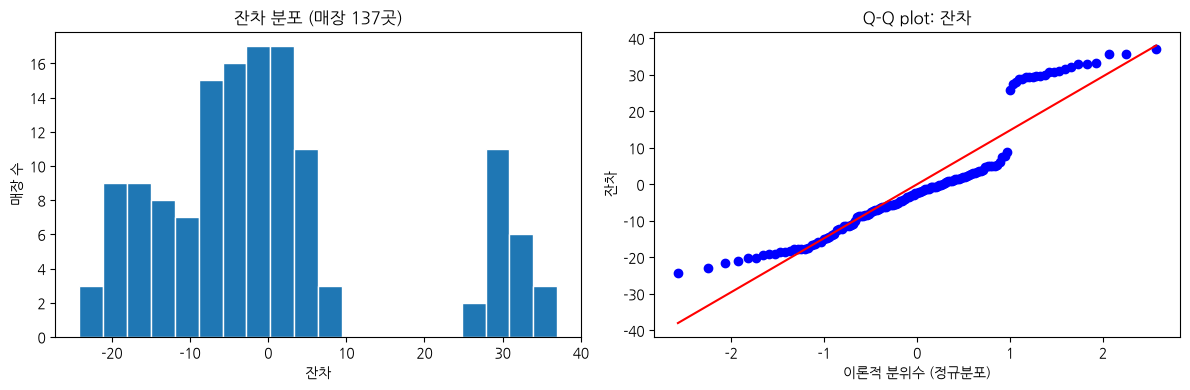

In [10]:
# 매장 단위로 요약: 매장 1곳당 4주 평균 1개
store_df = df_analysis.groupby(["LocationID", "Promotion"], as_index=False)["SalesInThousands"].mean()
print(store_df["Promotion"].value_counts().sort_index())

# 잔차 = 각 매장 값 - 해당 프로모션 그룹 평균
store_df["resid"] = store_df["SalesInThousands"] - store_df.groupby("Promotion")["SalesInThousands"].transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(store_df["resid"], bins=20, edgecolor="white")
axes[0].set_title(f"잔차 분포 (매장 {len(store_df)}곳)")
axes[0].set_xlabel("잔차")
axes[0].set_ylabel("매장 수")
stats.probplot(store_df["resid"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: 잔차")
axes[1].set_xlabel("이론적 분위수 (정규분포)")
axes[1].set_ylabel("잔차")
plt.tight_layout()
plt.show()

#### 등분산: 시각적 점검

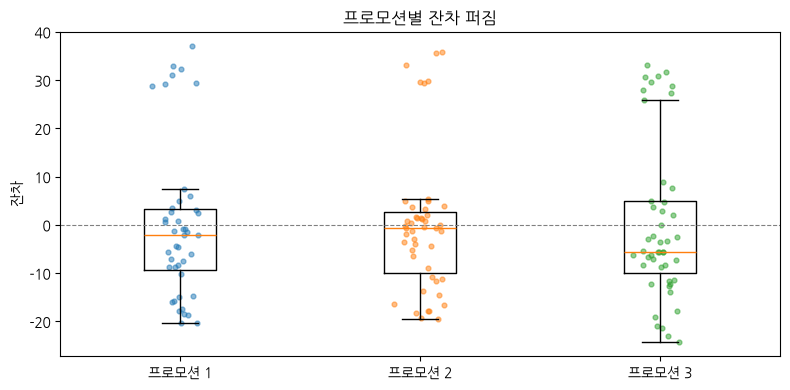

프로모션별 잔차 표준편차:
Promotion
1    16.03
2    14.50
3    16.38
Name: resid, dtype: float64


In [11]:
# 프로모션별 잔차의 퍼짐 비교 (잔차라서 그룹 간 평균 차이는 빠지고 퍼짐만 보임)
resid_by_promo = [store_df.loc[store_df["Promotion"] == p, "resid"] for p in sorted(store_df["Promotion"].unique())]
promo_labels = [f"프로모션 {p}" for p in sorted(store_df["Promotion"].unique())]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(resid_by_promo, tick_labels=promo_labels, showfliers=False)
for i, r in enumerate(resid_by_promo, start=1):
    ax.scatter(rng.normal(i, 0.05, len(r)), r, alpha=0.5, s=12)   # 개별 매장
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_ylabel("잔차")
ax.set_title("프로모션별 잔차 퍼짐")
plt.tight_layout()
plt.show()

print("프로모션별 잔차 표준편차:")
print(store_df.groupby("Promotion")["resid"].std().round(2))

#### 정규성·등분산: 통계적 점검

In [12]:
w, p_sw = stats.shapiro(store_df["resid"])
print(f"[정규성: 잔차 Shapiro-Wilk] W = {w:.3f}, p = {p_sw:.4f} → {'정규성 OK' if p_sw >= 0.05 else '정규성 위반'}")

promos = sorted(store_df["Promotion"].unique())
groups = [store_df.loc[store_df["Promotion"] == p, "SalesInThousands"].values for p in promos]
lev_stat, lev_p = stats.levene(*groups)   # 기본값 center='median' (이상치에 강함)
print(f"\n[등분산: Levene] stat = {lev_stat:.3f}, p = {lev_p:.4f} → {'등분산 OK' if lev_p >= 0.05 else '등분산 위반'}")

[정규성: 잔차 Shapiro-Wilk] W = 0.879, p = 0.0000 → 정규성 위반

[등분산: Levene] stat = 0.468, p = 0.6272 → 등분산 OK


#### 중심극한정리: 그룹 평균의 분포 확인

원데이터(잔차)는 정규가 아니지만, ANOVA가 비교하는 **그룹 평균**의 분포가 정규에 가까운지 부트스트랩으로 확인한다. (잔차 기준이라 그룹 간 평균 차이는 보이지 않음)

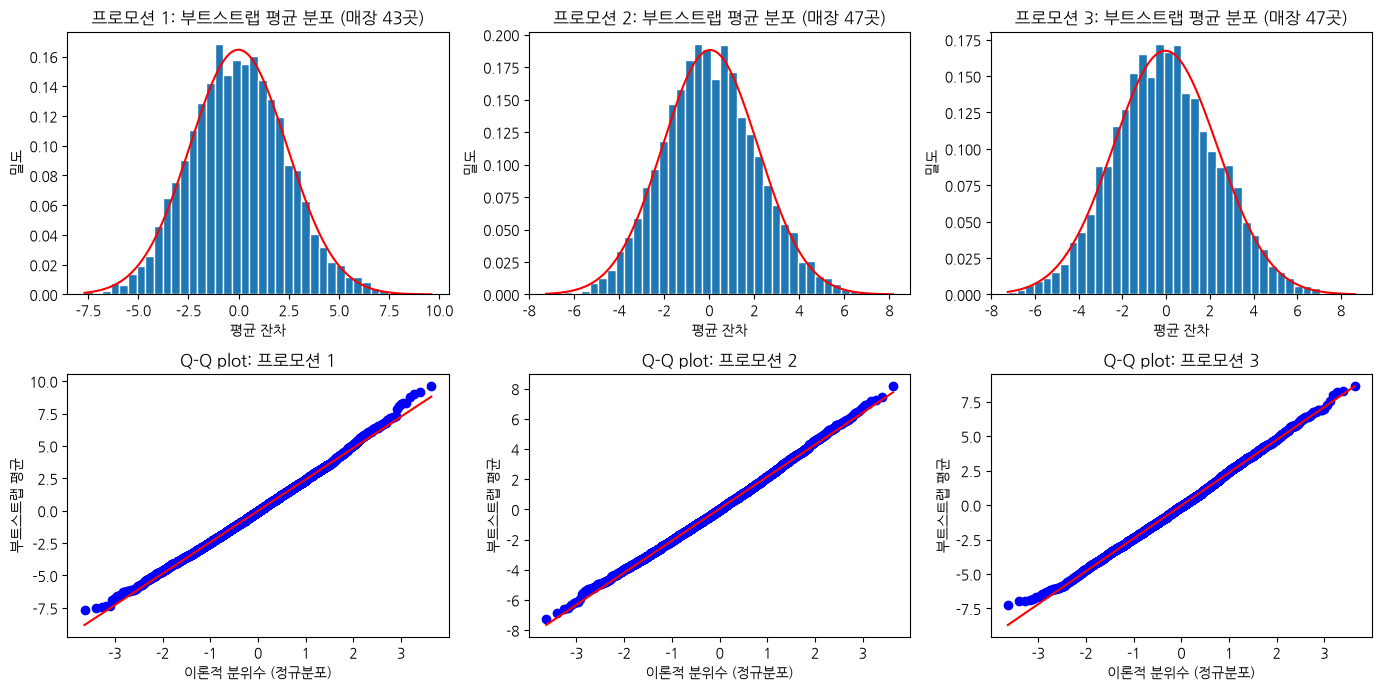

In [13]:
rng = np.random.default_rng(42)
n_boot = 5000

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, (label, r) in enumerate(zip(promo_labels, resid_by_promo)):
    r = r.values
    boot_means = rng.choice(r, size=(n_boot, len(r)), replace=True).mean(axis=1)   # 매장 n개를 복원추출해 평균 5000번

    axes[0, i].hist(boot_means, bins=40, density=True, edgecolor="white")
    xs = np.linspace(boot_means.min(), boot_means.max(), 200)
    axes[0, i].plot(xs, stats.norm.pdf(xs, boot_means.mean(), boot_means.std()), color="red")   # 정규분포 곡선
    axes[0, i].set_title(f"{label}: 부트스트랩 평균 분포 (매장 {len(r)}곳)")
    axes[0, i].set_xlabel("평균 잔차")
    axes[0, i].set_ylabel("밀도")

    stats.probplot(boot_means, dist="norm", plot=axes[1, i])
    axes[1, i].set_title(f"Q-Q plot: {label}")
    axes[1, i].set_xlabel("이론적 분위수 (정규분포)")
    axes[1, i].set_ylabel("부트스트랩 평균")
plt.tight_layout()
plt.show()

### 검정 선택: 일원 ANOVA + Tukey HSD (Kruskal-Wallis로 견고성 확인)

검정 방법으로 **일원 ANOVA**를 채택하고, 유의하면 **Tukey HSD**로 사후검정한다. 성공 지표인 '신메뉴 매출(`SalesInThousands`)'은 연속형이고, 비교할 집단은 '프로모션 3개'이며, 가설은 '세 그룹의 평균이 같은가'이기 때문이다. 정규성은 ANOVA 잔차로 확인했다. 잔차 히스토그램에서 대부분은 -25~10 구간에 모여 있지만 25~37 구간에 별도의 무리가 있는 두 봉우리 형태가 보였고, Q-Q plot에서도 오른쪽 끝이 직선에서 벗어나 계단처럼 위로 튀어 있었다. Shapiro-Wilk 검정에서도 정규성이 기각되었다(W = 0.879, p < 0.0001). 그러나 그룹당 매장이 43~47개로 충분하여 중심극한정리에 따라 그룹 평균의 분포는 정규에 가까워지고, 부트스트랩으로 확인한 그룹별 평균의 분포도 Q-Q plot에서 직선을 따랐다. 따라서 평균을 비교하는 ANOVA는 이 정도의 정규성 위반에 강건하다. 또한 프로모션별 잔차 박스플롯에서 퍼짐이 비슷했고(표준편차 14.50~16.38), 등분산도 기각되지 않았으며(Levene p = 0.6272) 그룹 크기도 비슷해, ANOVA가 취약한 조건(등분산 위반 + 그룹 크기 불균형)에도 해당하지 않는다. 다만 정규성 위반이 결론에 영향을 주는지 확인하기 위해 **Kruskal-Wallis** 검정을 함께 수행하고, 두 검정의 결론이 일치하는지 견고성을 확인한다.

# [4] 검정 수행하고 3종 세트로 보고

,프로모션,매장 수,평균,95% 신뢰구간 하한,95% 신뢰구간 상한
0,1,43,58.10,53.17,63.03
1,2,47,47.33,43.07,51.59
2,3,47,55.36,50.55,60.17


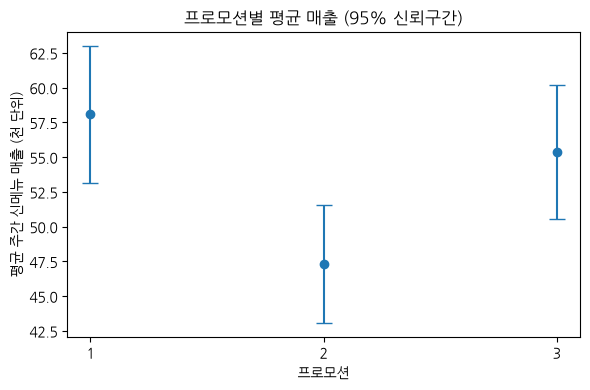

In [14]:
# 그룹별 평균과 95% 신뢰구간
promos = sorted(store_df["Promotion"].unique())
groups = [store_df.loc[store_df["Promotion"] == p, "SalesInThousands"].values for p in promos]

rows = []
for p, x in zip(promos, groups):
    m, se = x.mean(), stats.sem(x)
    lo, hi = stats.t.interval(0.95, len(x) - 1, loc=m, scale=se)
    rows.append({"프로모션": p, "매장 수": len(x), "평균": m, "95% 신뢰구간 하한": lo, "95% 신뢰구간 상한": hi})
summary = pd.DataFrame(rows).round(2)
display(summary)

# 평균 ± 95% 신뢰구간 그래프
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(summary["프로모션"], summary["평균"],
            yerr=[summary["평균"] - summary["95% 신뢰구간 하한"], summary["95% 신뢰구간 상한"] - summary["평균"]],
            fmt="o", capsize=6)
ax.set_xticks(promos)
ax.set_xlabel("프로모션")
ax.set_ylabel("평균 주간 신메뉴 매출 (천 단위)")
ax.set_title("프로모션별 평균 매출 (95% 신뢰구간)")
plt.tight_layout()
plt.show()

In [15]:
# ANOVA 전체 비교 + 효과크기 η²
f_stat, p_anova = stats.f_oneway(*groups)
df_between, df_within = len(groups) - 1, len(store_df) - len(groups)

# η² = 그룹 간 변동 / 전체 변동 (전체 매출 차이 중 프로모션이 설명하는 비율)
grand_mean = store_df["SalesInThousands"].mean()
ss_between = sum(len(x) * (x.mean() - grand_mean) ** 2 for x in groups)
ss_total = ((store_df["SalesInThousands"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total

print(f"F({df_between}, {df_within}) = {f_stat:.2f}, p = {p_anova:.4f}, η² = {eta_sq:.3f}")
print("→ 유의함: 사후검정(Tukey HSD) 진행" if p_anova < 0.05 else "→ 유의하지 않음: 사후검정 생략")


F(2, 134) = 5.85, p = 0.0037, η² = 0.080
→ 유의함: 사후검정(Tukey HSD) 진행


**전체 비교 결과 (ANOVA)**
- 프로모션 간 평균 신메뉴 매출에 유의한 차이가 있다(F(2, 134) = 5.85, p = 0.0037). 효과크기는 η² = 0.080으로, 매장 간 매출 차이의 약 8%를 프로모션이 설명한다(중간 효과).


In [16]:
# Tukey HSD 쌍별 비교 + 쌍별 효과크기(Cohen's d)
tukey = stats.tukey_hsd(*groups)
ci = tukey.confidence_interval(0.95)   # 다중 비교가 보정된 95% 신뢰구간

pair_rows = []
for i in range(len(promos)):
    for j in range(i + 1, len(promos)):
        a, b = groups[i], groups[j]
        pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
        pair_rows.append({
            "비교": f"프로모션 {promos[i]} vs {promos[j]}",
            "평균 차이": tukey.statistic[i, j],          # 앞 프로모션 평균 − 뒤 프로모션 평균
            "95% 신뢰구간 하한": ci.low[i, j],
            "95% 신뢰구간 상한": ci.high[i, j],
            "조정 p": tukey.pvalue[i, j],
            "Cohen's d": (a.mean() - b.mean()) / pooled_sd,
            "유의": "유의함" if tukey.pvalue[i, j] < 0.05 else "유의하지 않음",
        })
tukey_df = pd.DataFrame(pair_rows).round(3)
display(tukey_df)


,비교,평균 차이,95% 신뢰구간 하한,95% 신뢰구간 상한,조정 p,Cohen's d,유의
0,프로모션 1 vs 2,10.770,2.944,18.595,0.004,0.706,유의함
1,프로모션 1 vs 3,2.735,-5.091,10.560,0.686,0.169,유의하지 않음
2,프로모션 2 vs 3,-8.035,-15.685,-0.385,0.037,-0.519,유의함


**사후검정 결과 (Tukey HSD)**
- **프로모션 2의 매출이 가장 낮다.** 프로모션 1은 2보다 주간 신메뉴 매출이 평균 10.77(천 단위) 높았고(d = 0.71, 중간~큰 효과), 프로모션 3은 2보다 8.04 높았다(d = 0.52, 중간 효과).
- **프로모션 1과 3은 구분되지 않는다.** 1이 2.74 높았지만 신뢰구간(−5.09 ~ 10.56)이 0을 포함하고 폭이 넓어, 어느 쪽이 더 낫다고 말할 근거가 부족하다. 이는 두 프로모션이 같다는 의미가 아니다.
- **2 vs 3의 차이는 근거가 상대적으로 약하다.** 조정 p = 0.037로 유의수준에 가깝고 신뢰구간 상한(−0.39)이 0에 근접하므로, 다음 단계의 Kruskal-Wallis 견고성 확인에서 함께 점검한다.


In [17]:
# Kruskal-Wallis 견고성 확인: 정규성 가정 없이도 같은 결론인가?
h_stat, p_kw = stats.kruskal(*groups)
eps_sq = h_stat / (len(store_df) - 1)   # 효과크기 ε²

print(f"[전체 비교] Kruskal-Wallis H({df_between}) = {h_stat:.2f}, p = {p_kw:.4f}, ε² = {eps_sq:.3f}")
print("→ ANOVA와 결론 일치" if (p_anova < 0.05) == (p_kw < 0.05) else "→ ANOVA와 결론 불일치")

# 쌍별 비교: Mann-Whitney U + Bonferroni 보정 (3쌍 → p × 3)
mw_rows = []
for i in range(len(promos)):
    for j in range(i + 1, len(promos)):
        u_stat, p_mw = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
        p_bonf = min(p_mw * 3, 1.0)
        tukey_sig = tukey.pvalue[i, j] < 0.05
        mw_rows.append({
            "비교": f"프로모션 {promos[i]} vs {promos[j]}",
            "U": u_stat,
            "보정 p (Bonferroni)": p_bonf,
            "유의": "유의함" if p_bonf < 0.05 else "유의하지 않음",
            "Tukey와 일치": "일치" if (p_bonf < 0.05) == tukey_sig else "불일치",
        })
display(pd.DataFrame(mw_rows).round(4))


[전체 비교] Kruskal-Wallis H(2) = 17.33, p = 0.0002, ε² = 0.127
→ ANOVA와 결론 일치


,비교,U,보정 p (Bonferroni),유의,Tukey와 일치
0,프로모션 1 vs 2,1489.0,0.0003,유의함,일치
1,프로모션 1 vs 3,1178.0,0.5320,유의하지 않음,일치
2,프로모션 2 vs 3,704.0,0.0075,유의함,일치


**견고성 확인 결과 (Kruskal-Wallis)**
- 정규성 가정이 필요 없는 Kruskal-Wallis 검정에서도 프로모션 간 차이가 유의했다(H(2) = 17.33, p = 0.0002, ε² = 0.127). ANOVA와 결론이 일치한다.
- 쌍별 비교(Mann-Whitney U, Bonferroni 보정)에서도 1 vs 2(p = 0.0003)와 2 vs 3(p = 0.0075)은 유의하고, 1 vs 3(p = 0.532)은 유의하지 않아 세 쌍 모두 Tukey와 결론이 같았다.
- 특히 Tukey에서 경계에 있던 2 vs 3의 차이도 비모수 검정에서 더 분명하게 확인되어, "프로모션 2가 1·3보다 매출이 낮다"는 결론은 정규성 위반에도 견고하다.


### 결과 보고 (점추정 · 95% 신뢰구간 · 효과크기)

> **요약**: 프로모션 2의 평균 주간 신메뉴 매출이 1·3보다 낮았고, 1과 3은 구분되지 않았다. 이 결론은 정규성 가정이 필요 없는 비모수 검정에서도 같았다.

#### 전체 비교 (일원 ANOVA)

| 프로모션 | 매장 수 | 평균 (천 단위) | 95% 신뢰구간 |
|:---:|:---:|:---:|:---:|
| 1 | 43 | **58.10** | 53.17 ~ 63.03 |
| 2 | 47 | **47.33** | 43.07 ~ 51.59 |
| 3 | 47 | **55.36** | 50.55 ~ 60.17 |

`F(2, 134) = 5.85, p = .004, η² = 0.080` → 중간 효과, 매장 간 매출 차이의 약 8%를 프로모션이 설명

#### 쌍별 비교 (Tukey HSD)

| 비교 | 결과 | 차이 (천 단위) | 상대 차이 | 95% 신뢰구간 | 조정 p | Cohen's d |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 vs 2 | **1 > 2** | +10.77 | +22.8% | 2.94 ~ 18.60 | .004 | 0.71 (중간~큼) |
| 3 vs 2 | **3 > 2** | +8.04 | +17.0% | 0.39 ~ 15.69 | .037 | 0.52 (중간) |
| 1 vs 3 | 유의하지 않음 | +2.74 | +4.9% | −5.09 ~ 10.56 | .686 | 0.17 (작음) |

- 상대 차이는 비교 대상(뒤쪽 프로모션) 평균 대비 비율이다.
- 1 vs 3은 신뢰구간이 0을 포함하므로 어느 쪽이 더 낫다고 말할 근거가 부족하다(같다는 의미는 아님).

#### 견고성 확인 (참고)

| 검정 | 결과 | ANOVA·Tukey와 |
|:---:|:---:|:---:|
| Kruskal-Wallis (전체) | H(2) = 17.33, p < .001, ε² = 0.127 | 일치 |
| Mann-Whitney 1 vs 2 (Bonferroni) | p < .001 | 일치 |
| Mann-Whitney 2 vs 3 (Bonferroni) | p = .008 | 일치 |
| Mann-Whitney 1 vs 3 (Bonferroni) | p = .532 | 일치 |

- 네 검정 모두 ANOVA·Tukey와 결론이 같아, 정규성 위반이 결론을 바꾸지 않았다.

### 보조 분석: 프로모션 간 차이가 4주 동안 일관되게 나타나는가?

[2]에서 정한 수행 조건(주 분석에서 유의한 차이 확인)을 충족하여 수행한다. 주차별 추이와 순위를 시각적으로 확인하고, 격차의 변화는 매장별 4주 추세(기울기)를 프로모션 간에 비교하는 검정 한 번으로 확인한다.

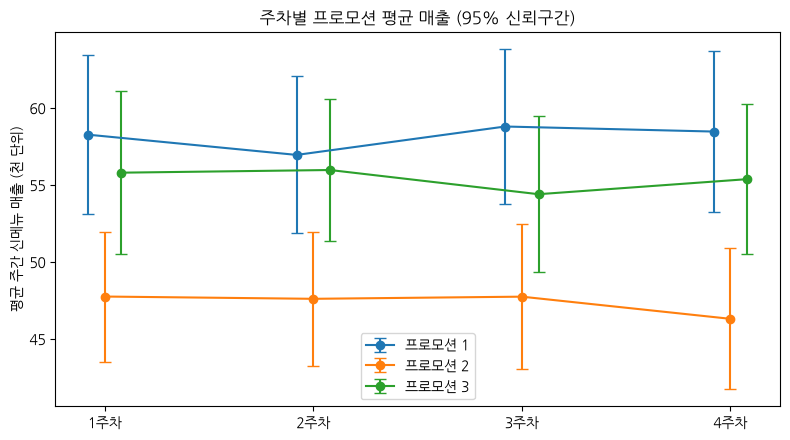

,프로모션 1,프로모션 2,프로모션 3
1주차,1,3,2
2주차,1,3,2
3주차,1,3,2
4주차,1,3,2


In [18]:
# 주차별·프로모션별 평균 신메뉴 매출과 95% 신뢰구간 (각 주차에서 매장 1곳 = 관측 1개)
weekly = (df_analysis.groupby(["Promotion", "week"])["SalesInThousands"]
          .agg(평균="mean", 표준오차="sem", 매장수="count").reset_index())
t_crit = stats.t.ppf(0.975, weekly["매장수"] - 1)
weekly["95% 신뢰구간 하한"] = weekly["평균"] - t_crit * weekly["표준오차"]
weekly["95% 신뢰구간 상한"] = weekly["평균"] + t_crit * weekly["표준오차"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, p in enumerate(promos):
    w = weekly[weekly["Promotion"] == p]
    x = w["week"] + (k - 1) * 0.08   # 신뢰구간이 겹치지 않게 살짝 옆으로 이동
    ax.errorbar(x, w["평균"],
                yerr=[w["평균"] - w["95% 신뢰구간 하한"], w["95% 신뢰구간 상한"] - w["평균"]],
                fmt="o-", capsize=4, label=f"프로모션 {p}")
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels([f"{wk}주차" for wk in [1, 2, 3, 4]])
ax.set_ylabel("평균 주간 신메뉴 매출 (천 단위)")
ax.set_title("주차별 프로모션 평균 매출 (95% 신뢰구간)")
ax.legend()
plt.tight_layout()
plt.show()

# 주차별 순위 (1 = 가장 높음)
rank = weekly.pivot(index="week", columns="Promotion", values="평균").rank(axis=1, ascending=False).astype(int)
rank.index = [f"{wk}주차" for wk in rank.index]
rank.columns = [f"프로모션 {p}" for p in rank.columns]
display(rank)

In [19]:
# 매장별 4주 추세(기울기): 주당 매출이 평균적으로 얼마나 늘거나 줄었는가
slopes = (df_analysis.groupby(["LocationID", "Promotion"])
          .apply(lambda g: stats.linregress(g["week"], g["SalesInThousands"]).slope, include_groups=False)
          .rename("주간 추세").reset_index())

slope_summary = slopes.groupby("Promotion")["주간 추세"].agg(["mean", "std", "count"]).round(3)
slope_summary.index.name = "프로모션"
slope_summary.columns = ["평균 추세 (주당 변화)", "표준편차", "매장 수"]
display(slope_summary)

# 추세가 프로모션별로 다르면 → 격차가 주차에 따라 커지거나 줄어든다는 뜻
slope_groups = [slopes.loc[slopes["Promotion"] == p, "주간 추세"].values for p in promos]
f_slope, p_slope = stats.f_oneway(*slope_groups)
print(f"[추세 비교] F({len(promos) - 1}, {len(slopes) - len(promos)}) = {f_slope:.2f}, p = {p_slope:.4f}")
print("→ 격차가 주차에 따라 변함" if p_slope < 0.05 else "→ 격차 변화가 유의하지 않음 (4주 동안 차이가 대체로 일정)")

,평균 추세 (주당 변화),표준편차,매장 수
프로모션,,,
1,0.245,1.933,43
2,-0.420,2.217,47
3,-0.284,1.670,47


[추세 비교] F(2, 134) = 1.44, p = 0.2414
→ 격차 변화가 유의하지 않음 (4주 동안 차이가 대체로 일정)


**보조 분석 결과**
- **순위는 4주 내내 같았다.** 매주 프로모션 1 > 3 > 2 순서였고, 그래프에서도 프로모션 2가 매주 가장 낮았다. 다만 1과 3은 매주 신뢰구간이 겹쳐, 1이 앞선 것은 숫자상 순서일 뿐이다(주 분석에서도 1 vs 3은 유의하지 않음).
- **격차는 커지거나 줄지 않았다.** 매장별 주당 매출 변화의 평균은 프로모션 1 +0.25, 2 −0.42, 3 −0.28로 모두 0에 가까웠고, 프로모션 간 차이도 유의하지 않았다(F(2, 134) = 1.44, p = 0.241).
- **결론**: "프로모션 2가 1·3보다 매출이 낮다"는 주 분석 결론은 4주 동안 일관되게 나타났고, 초반에만 차이가 났다가 사라지는 신기함 효과(novelty effect)의 징후도 보이지 않았다.
- **한계**: 관측 기간이 4주뿐이라 그 이후의 추세는 알 수 없다. 또한 추세 차이가 유의하지 않다는 것이 격차가 일정하다는 증명은 아니다.

### MDE: 이번 테스트로 구분할 수 있었던 최소 차이

1 vs 3이 유의하지 않았던 것이 "차이가 없어서"인지 "이 표본으로는 그 정도 차이를 잡아낼 수 없어서"인지 구분하기 위해 **MDE(최소 검출 효과)**를 계산한다.

- **MDE**: 유의수준 α에서 검정력 80%로(실제로 그만큼 차이가 있을 때 80% 확률로 유의하게 나오는) 검출할 수 있는 최소 평균 차이
- **그룹 안 퍼짐**: 매장 값의 공통 표준편차(ANOVA의 √MSE)를 쓴다.
- **유의수준**: 단일 비교(α = 0.05)와 [4]처럼 세 쌍을 비교할 때의 보정(α = 0.05 / 3, Bonferroni로 근사) 두 경우를 본다.

In [20]:
# MDE: 그룹당 매장 43~47곳으로 검정력 80%에서 검출할 수 있는 최소 평균 차이 (1 vs 3 기준)
from statsmodels.stats.power import TTestIndPower

power_calc = TTestIndPower()
power_target = 0.8
sd_within = np.sqrt((store_df["resid"] ** 2).sum() / (len(store_df) - len(promos)))   # 공통 표준편차 (√MSE)
n1, n3 = len(groups[0]), len(groups[2])
print(f"공통 표준편차 = {sd_within:.2f}, 매장 수: 프로모션 1 = {n1}, 프로모션 3 = {n3}")

mde_rows = []
for label, a in [("단일 비교", 0.05), ("세 쌍 보정 (Bonferroni)", 0.05 / 3)]:
    d_mde = power_calc.solve_power(nobs1=n1, ratio=n3 / n1, alpha=a, power=power_target)
    mde_rows.append({
        "유의수준": label,
        "α": round(a, 4),
        "MDE (Cohen's d)": round(d_mde, 2),
        "MDE (천 단위)": round(d_mde * sd_within, 2),
        "프로모션 3 평균 대비": f"{d_mde * sd_within / groups[2].mean():.1%}",
    })
display(pd.DataFrame(mde_rows))

# 실제로 관측된 1 vs 3 차이를 이 표본이 잡아낼 확률 (단일 비교 기준)
diff_13 = groups[0].mean() - groups[2].mean()
power_obs = power_calc.power(effect_size=diff_13 / sd_within, nobs1=n1, ratio=n3 / n1, alpha=0.05)
print(f"관측된 1 vs 3 차이 = {diff_13:.2f} (d = {diff_13 / sd_within:.2f}) → 이 크기의 차이를 검출할 확률(검정력) = {power_obs:.0%}")

공통 표준편차 = 15.65, 매장 수: 프로모션 1 = 43, 프로모션 3 = 47


,유의수준,α,MDE (Cohen's d),MDE (천 단위),프로모션 3 평균 대비
0,단일 비교,0.0500,0.60,9.35,16.9%
1,세 쌍 보정 (Bonferroni),0.0167,0.69,10.86,19.6%


관측된 1 vs 3 차이 = 2.73 (d = 0.17) → 이 크기의 차이를 검출할 확률(검정력) = 13%


In [21]:
# 2차 테스트(1 vs 3, 비교 1번 → α = 0.05) 표본 크기: 검출하려는 차이(MDE)에 따라 그룹당 몇 곳이 필요한가
base_mean = (groups[0].mean() + groups[2].mean()) / 2   # 1·3 평균 매출의 평균 (상대 차이의 기준)

n_rows = []
for pct in [0.05, 0.10, 0.15]:
    mde = pct * base_mean
    n_per_group = int(np.ceil(power_calc.solve_power(effect_size=mde / sd_within, alpha=0.05, power=power_target)))
    n_rows.append({
        "MDE (상대 차이)": f"{pct:.0%}",
        "MDE (천 단위)": round(mde, 2),
        "Cohen's d": round(mde / sd_within, 2),
        "그룹당 매장 수": n_per_group,
        "총 매장 수": 2 * n_per_group,
    })
display(pd.DataFrame(n_rows))
print(f"참고: 이번 테스트 전체 매장 수 = {len(store_df)}곳")

,MDE (상대 차이),MDE (천 단위),Cohen's d,그룹당 매장 수,총 매장 수
0,5%,2.84,0.18,479,958
1,10%,5.67,0.36,121,242
2,15%,8.51,0.54,55,110


참고: 이번 테스트 전체 매장 수 = 137곳


**MDE 결과**
- **이번 테스트의 MDE는 약 9.35(천 단위)였다.** 단일 비교 기준으로 1과 3의 차이가 프로모션 3 평균의 약 17% 이상이어야 80% 확률로 검출할 수 있었다. 세 쌍 보정을 적용하면 약 10.9(약 20%)로 더 커진다.
- **관측된 1 vs 3 차이(2.74, d = 0.17)는 MDE의 3분의 1 수준이다.** 이 크기의 차이가 실제로 있어도 이 표본으로 검출할 확률은 약 13%에 불과하다. 따라서 1 vs 3이 유의하지 않은 것은 "두 프로모션이 같다"는 근거가 아니라 **이 테스트가 그 정도 차이를 볼 만큼 크지 않았다**는 뜻이다.
- 참고로 MDE는 "80% 확률로 잡아낼 수 있는 크기"이지 유의 판정의 기준선이 아니다. 3 vs 2 차이(8.04)는 MDE보다 작지만 유의하게 나왔다.
- **2차 테스트에 필요한 규모**: 시장 보정 없이 지금과 같은 퍼짐이라면, 상대 차이 10%(약 5.7)를 검출하려면 그룹당 약 121곳(총 242곳), 5%(약 2.8)를 검출하려면 그룹당 약 479곳이 필요하다. 이번 테스트 전체(137곳)보다 훨씬 많으므로, 시장 보정이나 사전 매출 보정으로 퍼짐을 줄이는 설계가 중요하다.

# [5] 한 걸음 더 — B. 가정이 깨졌다면

[3]에서 잔차의 정규성이 깨졌다(Shapiro-Wilk p < 0.0001, 두 봉우리 분포). 이 상황에서 [4]의 결론이 **분석 방법**과 **이상치**에 따라 바뀌는지 확인한다.

1. **분포 진단**: 높은 매출 무리(이상치)는 어디서 왔나?
2. **세 방법 비교**: t-검정 / Mann-Whitney U / 부트스트랩 신뢰구간의 결론이 같은가?
3. **이상치 전후 비교**: 이상치를 빼도 결론이 유지되는가?
4. **시장 보정 분석** (사후 분석): 시장을 빼지 않고 모형에서 보정하면 결론이 달라지는가?

> [3]의 부트스트랩은 ANOVA 가정 점검용(잔차 평균의 분포 모양 확인)이었고, 여기서는 두 프로모션 **평균 차이의 신뢰구간 추정**에 사용한다.

### B-1. 분포 진단: 이상치는 어디서 왔나

잔차 20 초과 매장: 22곳 → 시장(MarketID): [3]


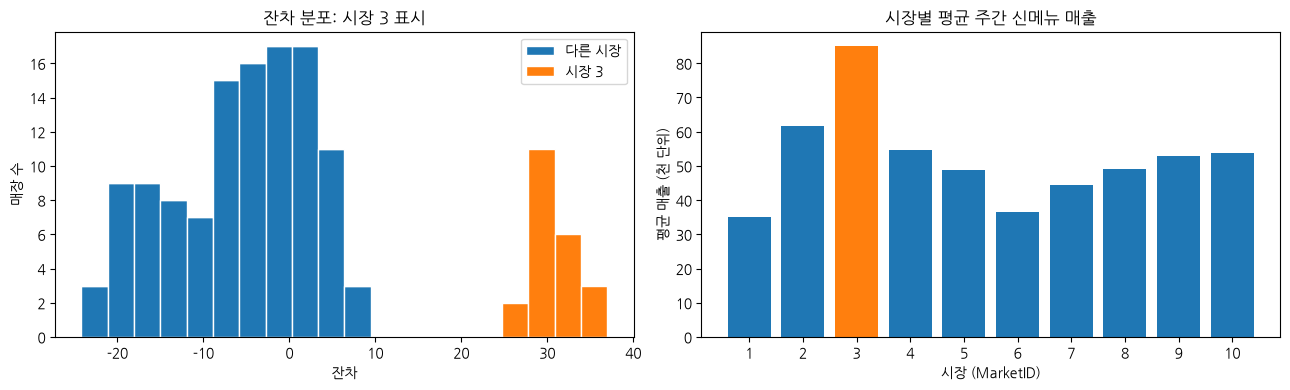


시장 3 매장의 프로모션별 분포:
프로모션 1    7
프로모션 2    6
프로모션 3    9


In [22]:
# 매장 단위 데이터에 시장 정보 붙이기
store_mk = df_analysis.groupby(["LocationID", "Promotion", "MarketID", "MarketSize"], as_index=False)["SalesInThousands"].mean()
store_mk["resid"] = store_mk["SalesInThousands"] - store_mk.groupby("Promotion")["SalesInThousands"].transform("mean")

# 잔차가 큰 매장(높은 매출 무리)은 어느 시장인가?
high = store_mk[store_mk["resid"] > 20]
print(f"잔차 20 초과 매장: {len(high)}곳 → 시장(MarketID): {sorted(high['MarketID'].unique().tolist())}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# (1) 잔차 히스토그램: 시장 3만 색을 다르게
is_m3 = store_mk["MarketID"] == 3
axes[0].hist([store_mk.loc[~is_m3, "resid"], store_mk.loc[is_m3, "resid"]], bins=20, stacked=True,
             edgecolor="white", label=["다른 시장", "시장 3"])
axes[0].set_title("잔차 분포: 시장 3 표시")
axes[0].set_xlabel("잔차")
axes[0].set_ylabel("매장 수")
axes[0].legend()

# (2) 시장별 평균 매출
market_mean = store_mk.groupby("MarketID")["SalesInThousands"].mean()
colors = ["tab:orange" if m == 3 else "tab:blue" for m in market_mean.index]
axes[1].bar(market_mean.index.astype(str), market_mean.values, color=colors)
axes[1].set_title("시장별 평균 주간 신메뉴 매출")
axes[1].set_xlabel("시장 (MarketID)")
axes[1].set_ylabel("평균 매출 (천 단위)")
plt.tight_layout()
plt.show()

# 시장 3 매장이 프로모션별로 고르게 나뉘어 있는가?
m3_by_promo = store_mk[is_m3]["Promotion"].value_counts().sort_index()
m3_by_promo.index = [f"프로모션 {p}" for p in m3_by_promo.index]
print("\n시장 3 매장의 프로모션별 분포:")
print(m3_by_promo.to_string())

**분포 진단 결과**
- 잔차 20을 넘는 매장 22곳이 **모두 시장 3**이었다. [3]에서 본 두 봉우리 중 오른쪽 봉우리가 이 시장이다.
- 시장 3의 평균 매출(약 85)은 다른 시장(35~62)보다 확연히 높다. 이상치는 측정 오류가 아니라 **매출 수준이 원래 높은 시장 하나**다.
- 시장 3 매장은 프로모션별로 7 / 6 / 9곳에 나뉘어 있어 한쪽에 몰려 있지 않다. 다만 프로모션 3에 조금 더 많다.

### B-2. 세 방법 비교 (전체 데이터)

- **t-검정**: Welch t-검정 (등분산 가정 없음)
- **Mann-Whitney U**: 순위 기반, 정규성 가정 없음
- **부트스트랩 신뢰구간**: 매장을 복원추출해 평균 차이를 10,000번 계산, 정규성 가정 없음
- 세 쌍을 비교하므로 [4]와 같이 **Bonferroni 보정**을 적용한다(보정 p = p × 3, 신뢰구간은 98.3%).

In [23]:
# 세 방법(t-검정 / Mann-Whitney U / 부트스트랩)으로 쌍별 비교하는 함수
n_pairs = 3
alpha_adj = 0.05 / n_pairs            # Bonferroni 보정 유의수준
conf_adj = 1 - alpha_adj              # 보정 신뢰수준 (약 98.3%)

def bootstrap_diff_ci(a, b, n_boot=10000, seed=42):
    """두 그룹 평균 차이(a - b)의 부트스트랩 백분위 신뢰구간"""
    rng = np.random.default_rng(seed)
    diffs = (rng.choice(a, size=(n_boot, len(a)), replace=True).mean(axis=1)
             - rng.choice(b, size=(n_boot, len(b)), replace=True).mean(axis=1))
    return np.quantile(diffs, [alpha_adj / 2, 1 - alpha_adj / 2])

def compare_three_methods(data):
    groups_ = {p: data.loc[data["Promotion"] == p, "SalesInThousands"].values for p in promos}
    rows = []
    for i, j in [(1, 2), (1, 3), (2, 3)]:
        a, b = groups_[i], groups_[j]
        t_res = stats.ttest_ind(a, b, equal_var=False)                 # Welch t-검정
        t_ci = t_res.confidence_interval(confidence_level=conf_adj)
        p_t = min(t_res.pvalue * n_pairs, 1.0)
        p_mw = min(stats.mannwhitneyu(a, b, alternative="two-sided").pvalue * n_pairs, 1.0)
        b_lo, b_hi = bootstrap_diff_ci(a, b)
        sig = [p_t < 0.05, p_mw < 0.05, not (b_lo <= 0 <= b_hi)]
        rows.append({
            "비교": f"{i} vs {j}",
            "평균 차이": round(a.mean() - b.mean(), 2),
            "t-검정 보정 p": round(p_t, 4),
            "t-검정 신뢰구간": f"{t_ci.low:.2f} ~ {t_ci.high:.2f}",
            "Mann-Whitney 보정 p": round(p_mw, 4),
            "부트스트랩 신뢰구간": f"{b_lo:.2f} ~ {b_hi:.2f}",
            "세 방법 결론": ("모두 유의함" if all(sig) else "모두 유의하지 않음" if not any(sig) else "엇갈림"),
        })
    return pd.DataFrame(rows)

print(f"보정 유의수준 = {alpha_adj:.4f}, 보정 신뢰수준 = {conf_adj:.1%}")

보정 유의수준 = 0.0167, 보정 신뢰수준 = 98.3%


In [24]:
# 전체 데이터(매장 137곳)로 세 방법 비교
methods_all = compare_three_methods(store_mk)
display(methods_all)

,비교,평균 차이,t-검정 보정 p,t-검정 신뢰구간,Mann-Whitney 보정 p,부트스트랩 신뢰구간,세 방법 결론
0,1 vs 2,10.77,0.0038,2.88 ~ 18.66,0.0003,3.20 ~ 18.60,모두 유의함
1,1 vs 3,2.73,1.0000,-5.61 ~ 11.08,0.5320,-5.37 ~ 10.91,모두 유의하지 않음
2,2 vs 3,-8.04,0.0407,-15.82 ~ -0.25,0.0075,-15.75 ~ -0.34,모두 유의함


**세 방법 비교 결과**

| 비교 | t-검정 보정 p | Mann-Whitney 보정 p | t-검정 신뢰구간 | 부트스트랩 신뢰구간 | 결론 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 vs 2 | 0.0038 | 0.0003 | 2.88 ~ 18.66 | 3.20 ~ 18.60 | 모두 유의함 |
| 1 vs 3 | 1.0000 | 0.5320 | −5.61 ~ 11.08 | −5.37 ~ 10.91 | 모두 유의하지 않음 |
| 2 vs 3 | 0.0407 | 0.0075 | −15.82 ~ −0.25 | −15.75 ~ −0.34 | 모두 유의함 |

- **세 방법의 결론이 세 쌍 모두 같다.** 정규성이 깨졌어도 방법에 따라 결론이 달라지지 않았다.
- **t-검정과 부트스트랩의 신뢰구간이 거의 같다.** 정규성을 가정하지 않는 부트스트랩과 결과가 비슷하므로, 정규성 위반이 평균 비교를 왜곡하지 않았다. [3]에서 판단한 ANOVA의 강건성이 실제로 확인되었다.
- 1 vs 3의 t-검정 보정 p가 1.0000인 것은 원래 p에 3을 곱한 값이 1을 넘어 1로 맞춘 것이다.

### B-3. 이상치 전후 비교: 시장 3을 빼면 결론이 바뀌는가

시장 3은 측정 오류가 아니라 실제 매장이므로 최종 분석에서는 제외하지 않는다. 여기서는 결론이 이 시장에 얼마나 의존하는지 보는 **민감도 확인**으로만 제외한다.

In [25]:
# 시장 3 제외(매장 115곳) 전후 비교
store_no_m3 = store_mk[store_mk["MarketID"] != 3]
print(f"시장 3 제외: 매장 {len(store_mk)}곳 → {len(store_no_m3)}곳")

# (1) 전체 비교: ANOVA
for label, data in [("전체", store_mk), ("시장 3 제외", store_no_m3)]:
    g = [data.loc[data["Promotion"] == p, "SalesInThousands"].values for p in promos]
    f_, p_ = stats.f_oneway(*g)
    gm = data["SalesInThousands"].mean()
    eta = sum(len(x) * (x.mean() - gm) ** 2 for x in g) / ((data["SalesInThousands"] - gm) ** 2).sum()
    print(f"[{label}] F(2, {len(data) - 3}) = {f_:.2f}, p = {p_:.4f}, η² = {eta:.3f}")

# (2) 쌍별 비교: 세 방법
methods_no_m3 = compare_three_methods(store_no_m3)
display(methods_no_m3)

# (3) 전후 결론 비교
before_after = pd.DataFrame({
    "비교": methods_all["비교"],
    "평균 차이 (전체)": methods_all["평균 차이"],
    "평균 차이 (시장 3 제외)": methods_no_m3["평균 차이"],
    "결론 (전체)": methods_all["세 방법 결론"],
    "결론 (시장 3 제외)": methods_no_m3["세 방법 결론"],
})
before_after["결론 변화"] = np.where(before_after["결론 (전체)"] == before_after["결론 (시장 3 제외)"], "같음", "바뀜")
display(before_after)

시장 3 제외: 매장 137곳 → 115곳
[전체] F(2, 134) = 5.85, p = 0.0037, η² = 0.080
[시장 3 제외] F(2, 112) = 12.96, p = 0.0000, η² = 0.188


,비교,평균 차이,t-검정 보정 p,t-검정 신뢰구간,Mann-Whitney 보정 p,부트스트랩 신뢰구간,세 방법 결론
0,1 vs 2,9.36,0.0000,4.82 ~ 13.89,0.0001,4.93 ~ 13.66,모두 유의함
1,1 vs 3,3.60,0.2018,-1.15 ~ 8.35,0.2052,-0.89 ~ 8.14,모두 유의하지 않음
2,2 vs 3,-5.76,0.0070,-10.23 ~ -1.28,0.0079,-10.04 ~ -1.53,모두 유의함


,비교,평균 차이 (전체),평균 차이 (시장 3 제외),결론 (전체),결론 (시장 3 제외),결론 변화
0,1 vs 2,10.77,9.36,모두 유의함,모두 유의함,같음
1,1 vs 3,2.73,3.60,모두 유의하지 않음,모두 유의하지 않음,같음
2,2 vs 3,-8.04,-5.76,모두 유의함,모두 유의함,같음


**이상치 전후 비교 결과**

| 비교 | 평균 차이 (전체 → 제외) | t-검정 신뢰구간 폭 (전체 → 제외) | 결론 |
|:---:|:---:|:---:|:---:|
| 1 vs 2 | 10.77 → 9.36 | 15.8 → 9.1 | 같음 (유의함) |
| 1 vs 3 | 2.73 → 3.60 | 16.7 → 9.5 | 같음 (유의하지 않음) |
| 2 vs 3 | −8.04 → −5.76 | 15.6 → 9.0 | 같음 (유의함) |

- **결론은 세 쌍 모두 그대로다.** "2가 가장 낮고, 1·3은 구분되지 않는다"는 결론은 시장 3에 의존하지 않는다.
- **신뢰구간 폭이 약 40% 줄었다.** 매장 수가 줄었는데도 구간이 좁아진 것은, 시장 3이 결론을 왜곡하기보다 그룹 안의 퍼짐을 키우는 **잡음** 역할을 했기 때문이다.
- **차이 크기는 조금 바뀌었다.** 2 vs 3 차이가 8.04에서 5.76으로 줄었는데, 매출이 높은 시장 3 매장이 프로모션 3에 조금 더 많아(9곳 vs 6곳) 전체 데이터에서 프로모션 3의 평균이 약간 부풀려져 있었기 때문이다.
- η²가 0.080에서 0.188로 커진 것은 프로모션 효과가 커져서가 아니라 시장 3을 빼면서 전체 퍼짐(분모)이 줄었기 때문이므로 두 값을 직접 비교하지 않는다.

### B-4. 시장 보정 분석: 시장을 빼지 않고 보정하면

B-1에서 매출 차이의 상당 부분이 시장에서 온다는 것을 확인했고, B-3에서는 시장 3 하나만 빼 보았다. 여기서는 시장을 하나도 빼지 않고, **시장을 설명변수로 넣은 회귀모형**으로 시장 간 매출 수준 차이를 보정한 뒤 프로모션 효과를 다시 추정한다.

- **모형**: `매출 ~ 프로모션 + 시장` (매장 단위, 시장은 범주형). 같은 시장 안에서 프로모션끼리 비교하는 것과 같다.
- **왜 필요한가**: 프로모션이 시장별로 고르게 배정되지 않았다면(예: 매출이 높은 시장에 특정 프로모션이 몰림) 보정 전 평균 차이에는 시장 차이가 섞인다. 또한 시장 차이를 빼면 그룹 안 퍼짐이 줄어 비교가 정밀해진다.
- **위치**: [2]에서 미리 정한 분석이 아니므로 **사후(탐색적) 분석**이다. 주 분석([4])의 결론을 대체하지 않고, 결론이 시장 보정 후에도 유지되는지와 정밀도가 얼마나 좋아지는지 확인하는 용도로 쓴다.
- 쌍별 비교는 B-2와 같이 **Bonferroni 보정**(보정 p = p × 3, 신뢰구간 98.3%)을 적용한다.

In [26]:
# 시장별 프로모션 배정 현황 (매장 수): 시장 안에서 고르게 나뉘었는가?
alloc = pd.crosstab(store_mk["MarketID"].rename("시장"), store_mk["Promotion"].rename("프로모션"), margins=True, margins_name="합계")
display(alloc)

# 이 정도 불균형이 무작위 배정에서 우연히 나올 수 있는가? (카이제곱 독립성 검정)
# 기대 빈도가 5 미만인 칸이 많아 근사 p 대신, 프로모션 라벨을 섞어 만든 순열 분포로 p를 구한다
ct = pd.crosstab(store_mk["MarketID"], store_mk["Promotion"])
chi2_obs = stats.chi2_contingency(ct)[0]
rng_perm = np.random.default_rng(0)
n_perm = 5000
chi2_perm = np.array([
    stats.chi2_contingency(pd.crosstab(store_mk["MarketID"].values, rng_perm.permutation(store_mk["Promotion"].values)))[0]
    for _ in range(n_perm)
])
p_perm = (chi2_perm >= chi2_obs).mean()
print(f"[시장 × 프로모션 배정 균형] χ² = {chi2_obs:.2f}, 순열 p = {p_perm:.3f}",
      "→ 우연으로 보기 어려운 불균형" if p_perm < 0.05 else "→ 무작위 배정에서 나올 수 있는 수준의 불균형")

프로모션,1,2,3,합계
시장,,,,
1,5,5,3,13
2,1,0,5,6
3,7,6,9,22
4,4,4,1,9
5,2,8,5,15
6,5,6,4,15
7,4,4,7,15
8,5,2,5,12
9,3,2,5,10


[시장 × 프로모션 배정 균형] χ² = 21.48, 순열 p = 0.266 → 무작위 배정에서 나올 수 있는 수준의 불균형


In [27]:
# 보정 전(프로모션만) vs 시장 보정(프로모션 + 시장) 회귀모형
import statsmodels.formula.api as smf
import statsmodels.api as sm

model_raw = smf.ols("SalesInThousands ~ C(Promotion)", data=store_mk).fit()
model_mkt = smf.ols("SalesInThousands ~ C(Promotion) + C(MarketID)", data=store_mk).fit()

# 시장 보정 모형의 분산분석표 (Type II: 각 요인을 다른 요인 보정 후 검정)
anova_mkt = sm.stats.anova_lm(model_mkt, typ=2)
anova_mkt.index = ["프로모션", "시장", "잔차"]
display(anova_mkt.round(4))

# 시장을 보정하면 그룹 안 퍼짐이 얼마나 줄어드는가
fit_cmp = pd.DataFrame({
    "모형": ["프로모션만 (보정 전)", "프로모션 + 시장 (시장 보정)"],
    "잔차 표준편차": [np.sqrt(model_raw.mse_resid), np.sqrt(model_mkt.mse_resid)],
    "R²": [model_raw.rsquared, model_mkt.rsquared],
}).round(3)
display(fit_cmp)

,sum_sq,df,F,PR(>F)
프로모션,2031.2608,2.0,151.2538,0.0
시장,31966.0789,9.0,528.9535,0.0
잔차,839.3428,125.0,NaN,NaN


,모형,잔차 표준편차,R²
0,프로모션만 (보정 전),15.647,0.080
1,프로모션 + 시장 (시장 보정),2.591,0.976


In [28]:
# 쌍별 비교: 보정 전 vs 시장 보정 (Bonferroni, 98.3% 신뢰구간)
def promo_contrast(model, a, b):
    """회귀모형에서 프로모션 a − b의 평균 차이, Bonferroni 신뢰구간, 보정 p"""
    names = list(model.params.index)
    L = np.zeros(len(names))
    for p, sign in [(a, 1), (b, -1)]:
        if p != promos[0]:                       # 기준(프로모션 1)은 계수가 없음
            L[names.index(f"C(Promotion)[T.{p}]")] += sign
    res = model.t_test(L)
    lo, hi = res.conf_int(alpha=alpha_adj)[0]
    return float(res.effect[0]), lo, hi, min(float(res.pvalue) * n_pairs, 1.0)

adj_rows = []
for a, b in [(1, 2), (1, 3), (2, 3)]:
    d0, lo0, hi0, p0 = promo_contrast(model_raw, a, b)
    d1, lo1, hi1, p1 = promo_contrast(model_mkt, a, b)
    adj_rows.append({
        "비교": f"{a} vs {b}",
        "차이 (보정 전)": round(d0, 2),
        "신뢰구간 (보정 전)": f"{lo0:.2f} ~ {hi0:.2f}",
        "보정 p (보정 전)": round(p0, 4),
        "차이 (시장 보정)": round(d1, 2),
        "신뢰구간 (시장 보정)": f"{lo1:.2f} ~ {hi1:.2f}",
        "보정 p (시장 보정)": round(p1, 4),
        "결론 변화": "같음" if (p0 < 0.05) == (p1 < 0.05) else "바뀜",
    })
display(pd.DataFrame(adj_rows))

# 시장 보정 모형의 잔차 정규성 (참고)
w_mkt, p_sw_mkt = stats.shapiro(model_mkt.resid)
print(f"[시장 보정 모형 잔차 Shapiro-Wilk] W = {w_mkt:.3f}, p = {p_sw_mkt:.4f}")

,비교,차이 (보정 전),신뢰구간 (보정 전),보정 p (보정 전),차이 (시장 보정),신뢰구간 (시장 보정),보정 p (시장 보정),결론 변화
0,1 vs 2,10.77,2.76 ~ 18.77,0.0042,9.72,8.36 ~ 11.07,0.0,같음
1,1 vs 3,2.73,-5.27 ~ 10.74,1.0000,4.92,3.55 ~ 6.30,0.0,바뀜
2,2 vs 3,-8.04,-15.86 ~ -0.21,0.0421,-4.79,-6.18 ~ -3.41,0.0,같음


[시장 보정 모형 잔차 Shapiro-Wilk] W = 0.973, p = 0.0076


In [29]:
# 시장마다 따로 본 프로모션 간 차이: 방향이 시장마다 일관되는가?
by_mkt = store_mk.pivot_table(index="MarketID", columns="Promotion", values="SalesInThousands")
diff_mkt = pd.DataFrame({
    "1 − 2": by_mkt[1] - by_mkt[2],
    "1 − 3": by_mkt[1] - by_mkt[3],
    "3 − 2": by_mkt[3] - by_mkt[2],
}).round(2)
diff_mkt.index.name = "시장"
display(diff_mkt)
for col in diff_mkt.columns:
    s = diff_mkt[col].dropna()
    print(f"{col}: 비교 가능한 시장 {len(s)}곳 중 {(s > 0).sum()}곳에서 양수")

# 프로모션 효과가 시장마다 다른가? (상호작용 검정)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # 시장 2에 프로모션 2 매장이 없어 일부 조합이 비어 있음
    model_int = smf.ols("SalesInThousands ~ C(Promotion) * C(MarketID)", data=store_mk).fit()
    int_test = sm.stats.anova_lm(model_mkt, model_int)
p_int = int_test["Pr(>F)"].iloc[1]
print(f"\n[상호작용 검정] F = {int_test['F'].iloc[1]:.2f}, p = {p_int:.4f}",
      "→ 프로모션 효과가 시장마다 다름" if p_int < 0.05 else "→ 시장마다 효과가 다르다는 근거 없음")

,1 − 2,1 − 3,3 − 2
시장,,,
1,10.57,6.73,3.84
2,NaN,4.61,NaN
3,10.06,4.73,5.33
4,7.99,6.69,1.31
5,9.60,4.68,4.92
6,8.07,3.90,4.17
7,10.76,5.95,4.81
8,8.64,1.79,6.85
9,6.69,4.78,1.91


1 − 2: 비교 가능한 시장 9곳 중 9곳에서 양수
1 − 3: 비교 가능한 시장 10곳 중 10곳에서 양수
3 − 2: 비교 가능한 시장 9곳 중 9곳에서 양수

[상호작용 검정] F = 0.78, p = 0.7083 → 시장마다 효과가 다르다는 근거 없음


In [30]:
# 시장 보정 시 MDE와 2차 테스트 표본 크기 (MDE 소절과 같은 조건: 검정력 80%, α = 0.05)
sd_mkt = np.sqrt(model_mkt.mse_resid)
d_mde = power_calc.solve_power(nobs1=n1, ratio=n3 / n1, alpha=0.05, power=power_target)
print(f"잔차 표준편차: 보정 전 {sd_within:.2f} → 시장 보정 {sd_mkt:.2f}")
print(f"이번 테스트 규모의 MDE: 보정 전 {d_mde * sd_within:.2f} → 시장 보정 {d_mde * sd_mkt:.2f}")

ss_rows = []
for pct in [0.05, 0.10, 0.15]:
    mde = pct * base_mean
    n_raw = int(np.ceil(power_calc.solve_power(effect_size=mde / sd_within, alpha=0.05, power=power_target)))
    n_mkt = int(np.ceil(power_calc.solve_power(effect_size=mde / sd_mkt, alpha=0.05, power=power_target)))
    ss_rows.append({"MDE (상대 차이)": f"{pct:.0%}", "MDE (천 단위)": round(mde, 2),
                    "그룹당 매장 수 (보정 전)": n_raw, "그룹당 매장 수 (시장 보정)": n_mkt})
display(pd.DataFrame(ss_rows))
print("※ 시장 보정 값은 회귀 자유도(시장 수)를 무시한 근사이며, 실제로는 시장마다 두 프로모션을 모두 배정해야 이 정밀도를 얻을 수 있다.")

잔차 표준편차: 보정 전 15.65 → 시장 보정 2.59
이번 테스트 규모의 MDE: 보정 전 9.35 → 시장 보정 1.55


,MDE (상대 차이),MDE (천 단위),그룹당 매장 수 (보정 전),그룹당 매장 수 (시장 보정)
0,5%,2.84,479,15
1,10%,5.67,121,5
2,15%,8.51,55,3


※ 시장 보정 값은 회귀 자유도(시장 수)를 무시한 근사이며, 실제로는 시장마다 두 프로모션을 모두 배정해야 이 정밀도를 얻을 수 있다.


**시장 보정 분석 결과**
- **시장별 배정에 우연 수준의 불균형이 있었다.** 시장 2에는 프로모션 2 매장이 한 곳도 없고(1 / 0 / 5곳), 시장 10은 프로모션 2에 몰려 있다(7 / 10 / 3곳). 다만 이 정도 불균형은 무작위 배정에서도 나올 수 있는 수준이어서(순열 p ≈ 0.27), [1]의 무작위 배정 가정과 어긋나지는 않는다. 그래도 시장 간 매출 차이가 워낙 커서, 이 작은 불균형만으로도 보정 전 평균 차이에 시장 구성 차이가 섞인다.
- **매장 간 매출 차이의 대부분은 시장 차이였다.** 시장을 넣자 R²가 0.080에서 0.976으로 올랐고, 잔차 표준편차가 15.65에서 2.59로 약 6분의 1로 줄었다. 프로모션 효과도 시장 보정 후 매우 뚜렷했다(F(2, 125) = 151.3, p < 0.0001).
- **"프로모션 2가 가장 낮다"는 결론은 유지되었다.** 1 vs 2는 9.72(98.3% 신뢰구간 8.36 ~ 11.07), 3 vs 2는 4.79(3.41 ~ 6.18) 차이로 모두 유의했다. 3 vs 2 차이가 8.04에서 4.79로 줄어든 것은, B-3에서 본 것처럼 매출이 높은 시장의 매장이 프로모션 3에 더 많았기 때문이다.
- **1 vs 3은 결론이 바뀌었다.** 보정 전에는 유의하지 않았지만(2.73, 신뢰구간 −5.27 ~ 10.74), 시장 보정 후 **프로모션 1이 3보다 4.92 높고**(3.55 ~ 6.30, 보정 p < 0.0001) 신뢰구간이 0을 포함하지 않는다. 보정 전 프로모션 3 평균(55.36) 대비 약 9% 수준이다.
- **시장마다 따로 본 방향도 대체로 일관된다.** 1 − 3 차이는 10개 시장 모두에서, 1 − 2와 3 − 2 차이는 비교 가능한 9개 시장 모두에서 양수였다. 다만 시장 × 프로모션 칸에 매장이 1~2곳뿐인 경우가 있어(예: 시장 2의 프로모션 1, 시장 4의 프로모션 3) 시장별 차이 하나하나는 불안정하므로, 이 표는 보조 근거로만 본다.
- **시장마다 효과가 다르다는 근거는 찾지 못했다.** 상호작용 검정은 유의하지 않았지만(p = 0.708), 칸이 작아 검정력이 낮으므로 효과가 모든 시장에서 같다는 뜻은 아니다.
- **시장을 보정하면 2차 테스트 규모가 크게 줄어든다.** 이번 테스트 규모의 MDE가 9.35에서 약 1.55로 줄고, 상대 차이 10%를 검출하는 데 필요한 매장이 그룹당 121곳에서 약 5곳으로 줄어든다. 다만 이 값은 시장 수(자유도)를 무시한 근사이고, 이번 데이터에서 추정한 퍼짐이 2차 테스트에서도 같다고 가정한 값이라 낙관적일 수 있다.
**주의할 점**
- **사후 분석이다.** [2]에서 미리 정하지 않은 분석이므로, 1 > 3은 **강한 신호이지만 확정 결론이 아니라 2차 테스트로 확인할 가설**로 다룬다.
- **시장이 10개뿐이고 칸이 작다.** 프로모션이 매장 단위로 배정되어 시장 안 비교로 프로모션 효과를 추정할 수는 있지만(시장 보정에 드는 자유도는 9개), 시장별 효과나 상호작용을 따로 말하기에는 매장 수가 부족하고, 다른 시장으로 일반화하는 근거도 약하다.
- **같은 시장 안 퍼짐이 매우 작다.** 시장 보정 후 잔차 표준편차는 2.59로 보정 전(15.65)의 약 6분의 1이다. 시장 보정 시 표본 크기 계산은 이 값이 2차 테스트에서도 같다고 가정하지만, 매장 137곳·시장 10개에서 한 번 추정한 값이므로 그대로 믿기 어렵다. 표본 크기는 보정 전 값과 시장 보정 값 사이에서 보수적으로 정한다.
- **보정 후 잔차의 정규성도 완전하지 않다**(Shapiro-Wilk p ≈ 0.008).

### 결론

> 정규성이 깨진 상황에서도 t-검정, Mann-Whitney U, 부트스트랩의 결론이 모두 같았고, 이상치의 원인인 시장 3을 빼도 결론이 유지되었다. 시장 3은 결론을 왜곡하지 않았으며 비교를 덜 정밀하게 만드는 잡음이었다.

- **시장 보정(B-4)**: 시장을 빼지 않고 보정하자 그룹 안 퍼짐이 약 6분의 1로 줄었고, "프로모션 2가 가장 낮다"는 결론은 유지되었다. 판단을 보류했던 1 vs 3은 시장 보정 후 1이 3보다 4.92 높게 나타났고, 시장별로 본 방향도 대체로 일관되었다. 다만 미리 정하지 않은 사후 분석이고 시장이 10개뿐이므로, 2차 테스트로 확인할 가설로 다룬다.
- **시사점**: 시장 간 매출 차이가 커서, 시장을 고려하지 않은 분석은 정밀도가 크게 떨어진다. 다음 실험에서는 시장별로 나눠 프로모션을 배정(층화 무작위 배정)하고 시장을 보정한 분석을 주 분석으로 미리 정해야 한다.

# [6] 의사결정

### 1. 질문과 가설
- **질문**: 세 가지 프로모션 중 어느 것을 쓰느냐에 따라 신메뉴 매출이 달라지는가?
- $H_0$: 세 프로모션을 적용한 매장들의 평균 신메뉴 매출(매장별 주간 매출의 4주 평균)은 모두 같다.
- $H_1$: 적어도 한 프로모션의 평균 신메뉴 매출은 나머지와 다르다.
- **유의수준** $\alpha = 0.05$, **양측 검정**. 보조 질문(차이가 4주 동안 일관되는가)은 주 분석이 유의할 때만 수행하기로 미리 정했다.

### 2. 데이터 위생 점검
- 548행(매장 137곳 × 4주)에서 결측·중복·배정 불일치(한 매장에 프로모션이 섞인 경우)가 없었다.
- **SRM**: 배정 단위인 매장 기준 43 / 47 / 47곳으로 균등 배정과 다르지 않았다(p = 0.890).
- **공변량 균형**: 시장 규모 비율과 매장 연령이 프로모션 간 비슷하여 무작위 배정 가정과 어긋나는 점이 없었다.
- **정제**: 제거한 데이터 없이 548행 전체를 사용했고, 가짜 반복을 피하기 위해 매장별 4주 평균으로 요약하여 매장 137곳을 분석 단위로 했다.

### 3. 검정 선택 근거
- 지표가 연속형이고, 집단이 3개이며, 가설이 평균 비교이므로 **일원 ANOVA + Tukey HSD**를 선택했다.
- 잔차의 정규성은 위반되었으나(Shapiro-Wilk p < 0.0001, 두 봉우리 분포), 그룹당 매장이 43~47곳으로 충분하고 부트스트랩으로 본 그룹 평균의 분포가 정규에 가까웠으며 등분산도 충족되어(Levene p = 0.627) ANOVA가 강건하다고 판단했다.
- 정규성 위반의 영향을 확인하기 위해 **Kruskal-Wallis**를 함께 수행했다.
- 정규성 점검 후, 주 검정 결과를 보기 전에 결정 규칙을 한 번 수정했다(정규성 위반 시 Kruskal-Wallis → 그룹당 n이 충분하면 ANOVA + Kruskal-Wallis 견고성 확인). 수정 시점과 이유는 [3]의 '결정 규칙 수정 기록'에 남겼고, 처음 규칙의 검정과 결론이 일치했다.

### 4. 결과

| 비교 | 평균 차이 (천 단위) | 상대 차이 | 95% 신뢰구간 | 조정 p | 효과크기 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 전체 (ANOVA) | — | — | — | .004 | η² = 0.080 (중간) |
| 1 vs 2 | +10.77 | +22.8% | 2.94 ~ 18.60 | .004 | d = 0.71 |
| 3 vs 2 | +8.04 | +17.0% | 0.39 ~ 15.69 | .037 | d = 0.52 |
| 1 vs 3 | +2.74 | +4.9% | −5.09 ~ 10.56 | .686 | d = 0.17 |

- **프로모션 2의 매출이 1·3보다 낮았고, 1과 3은 구분되지 않았다.**
- 이 결론은 비모수 검정(Kruskal-Wallis, Mann-Whitney U), t-검정, 부트스트랩 신뢰구간에서 모두 같았고, 이상치의 원인인 시장 3을 빼도 유지되었다.
- 4주 동안 순위(1 > 3 > 2)가 매주 같았고, 격차가 커지거나 줄지 않았다(추세 비교 p = 0.241).
- **1 vs 3을 구분하지 못한 것은 표본이 작았기 때문이다.** 이번 테스트의 MDE는 약 9.35(평균의 약 17%)로, 관측된 차이(2.74)를 검출할 확률은 약 13%였다.
- **사후 분석(시장 보정)**: 시장 간 매출 차이를 보정하자 잔차 표준편차가 15.65에서 2.59로 줄었고, "2가 가장 낮다"는 결론은 유지되었다. 1 vs 3은 **1이 3보다 4.92 높게**(98.3% 신뢰구간 3.55 ~ 6.30, 약 9%) 나타났다. 다만 [2]에서 미리 정하지 않은 분석이고 시장이 10개뿐이어서, 확정 결론이 아닌 가설로 다룬다.

### 5. 의사결정: 데이터 추가 수집 (프로모션 1 > 3을 확인하는 2차 테스트)
이 테스트는 일부 시장에서만 진행되어, 프로모션을 정한 뒤 더 넓게 출시하기 위한 사전 테스트로 해석된다. 따라서 넓게 출시하기 전에 남은 불확실성을 줄이는 방향으로 결정한다.

- **프로모션 2는 후보에서 제외한다.** 1·3보다 매출이 낮다는 결론이 분석 방법, 이상치 여부, 주차에 관계없이 일관되었다.
- **프로모션 1과 3은 미리 정한 주 분석으로는 우열을 판단할 수 없다.** 차이가 유의하지 않고 신뢰구간(−5.09 ~ 10.56)이 넓다.
- **다만 사후 시장 보정 분석에서 1이 3보다 약 9% 높다는 강한 신호가 나왔으므로, 2차 테스트는 "프로모션 1이 3보다 낫다"를 확인하는 테스트로 설계한다.** 사후 분석 결과만으로 바로 1을 채택하지 않는 이유는, 미리 정하지 않은 분석으로 결정을 바꾸면 [2]에서 세운 원칙과 어긋나고, 시장이 10개뿐이라 다른 시장에서도 같은 차이가 나타날지 알 수 없기 때문이다.

**2차 테스트 설계**
- **핵심 질문 (1순위)**: 프로모션 1이 3보다 신메뉴 매출이 높은가 (사후 시장 보정 분석에서 나온 가설을 확인)
  - **시장별 층화 무작위 배정 + 시장 보정을 주 분석으로 사전 지정**: 시장 간 매출 차이가 커서(시장 보정 시 잔차 표준편차 15.65 → 2.59) 모든 시장에서 1과 3을 비슷한 수로 나눠 배정하고, `매출 ~ 프로모션 + 시장` 모형을 주 분석으로 테스트 전에 정해 둔다. 이번처럼 한 시장에 특정 프로모션이 없는 일(시장 2의 프로모션 2)을 막을 수 있다.
  - **사전 매출 수집**: 이번 데이터에는 프로모션 전 매출이 없었다. 테스트 전 몇 주의 매출을 수집해 분석할 때 보정하면 같은 매장 수로도 더 정밀하게 비교할 수 있다.
  - **표본 크기 사전 결정**: 검출하고 싶은 최소 차이(MDE)와 검정력 80%를 기준으로 매장 수(가능하면 시장 수도)를 테스트 전에 정하고, 결과를 보며 중간에 늘리지 않는다. 이번 테스트의 MDE는 약 9.35(평균의 약 17%)로 관측된 1 vs 3 차이(2.74)보다 훨씬 컸다. 상대 차이 10%를 검출하려면 시장을 보정하지 않을 때 그룹당 약 121곳, 시장 보정 퍼짐을 그대로 쓰면 약 5곳이 필요하다. 시장 보정 값은 근사이고, 이번 데이터에서 추정한 작은 퍼짐(잔차 표준편차 2.59)이 2차 테스트에서도 같다고 가정한 값이라 낙관적일 수 있으므로, 사전 매출 등으로 실제 시장 보정 후 퍼짐을 다시 추정해 두 값 사이에서 **보수적으로** 정한다. 사후 분석에서 본 차이(약 9%)보다 작은 차이도 잡을 수 있도록 MDE를 그보다 작게 잡는다.
- **추가 질문 (선택)**: 프로모션이 비용만큼 매출을 올리는가(ROI)
  - 프로모션을 적용하지 않는 소규모 **대조군**을 두고, 신메뉴 매출뿐 아니라 **매장 전체 매출**과 **프로모션 비용**을 함께 측정한다.
- **설계 시 고려할 트레이드오프**: 같은 시장 안에서 나눠 배정하면 정밀도는 높지만 손님이 겹쳐 프로모션 효과가 섞일(오염) 위험이 있다. 시장 단위로 배정하면 오염은 줄지만 시장 수가 적어 정밀도가 떨어진다.

### 6. 한계
- **대조군이 없다.** 프로모션 간 상대 비교만 가능하며, 각 프로모션이 프로모션을 하지 않았을 때보다 매출을 올렸는지는 알 수 없다.
- **프로모션 무작위 배정은 가정이다.** 데이터 설명에는 시장의 무작위 선정만 명시되어 있어, 공변량 균형 점검으로 간접 확인했을 뿐이다.
- **주 분석은 시장을 보정하지 않았고, 시장 보정은 사후 분석이다.** 매출 차이의 대부분이 시장에서 와서 주 분석의 정밀도가 낮았고, 프로모션이 시장별로 고르게 배정되지 않아 차이 크기 추정에 영향을 주었다(3 vs 2: 8.04 → 시장 보정 시 4.79). 시장 보정 분석은 [2]에서 미리 정하지 않았으므로 그 결과(1 > 3)는 가설로만 다룬다.
- **프로모션 전 매출(기준선)이 없고 시장이 10개뿐이다.** 매장별 기본 매출 차이를 보정할 수 없었고, 시장 3처럼 특이한 시장 하나가 결과에 큰 영향을 줄 수 있다.
- **관측 기간이 4주뿐이다.** 그 이후의 장기 효과나 추세는 알 수 없다.
- **신메뉴 매출만 측정했다.** 기존 메뉴 매출 감소(잠식), 프로모션 비용, 이익은 알 수 없으며, 매출의 통화 단위도 명시되어 있지 않다.
- **1 vs 3이 유의하지 않다는 것은 두 프로모션이 같다는 뜻이 아니다.** 이 테스트의 MDE(약 9.35)가 관측된 차이(2.74)보다 훨씬 커서, 그 정도 차이가 실제로 있어도 검출할 확률이 약 13%였다.